# WAFER-GUARD · Fab-7 Excursion Detector — audited & repaired

This notebook replaces the release candidate `bnypi.ipynb`. It is in two parts:

* **Part A — Audit.** It re-runs the release candidate exactly as written and reproduces its reported
  F1 ≥ 0.90. It then measures, with numbers, why that score is an artifact.
* **Part B — Repair.** A causality-safe pipeline (the same supervised-autoencoder architecture) is trained only on the
  past, tuned only on the past, and evaluated **once** on the most recent 20 % of lots at their
  **natural defect prevalence**.

| # | Silent defect (release candidate) | Category | Repair |
|---|---|---|---|
| 1 | SMOTE run **before** the train/test split, plus a random (time-shuffled) split, plus imputer and scaler fitted on **all** rows | data leakage | chronological split first; every statistic fitted on the training window only; no synthetic rows; test kept at natural prevalence |
| 2 | Loader yields `[B, 1, F]`, model returns `[B, F]`, so `(x̂ − x)` silently broadcasts to `[B, B, F]` | corrupted loss gradients | flat `[B, F]` tensors, masked MSE with hard shape assertions |
| 3 | Probe Station PS-L: `sensor_0 = 0.0` sentinel and `sensor_1 ∈ {100, 200, 300}` firmware codes treated as real continuous readings | invariant blindness | sentinel and code removed from the continuous block (never scaled, never imputed, excluded from reconstruction); code one-hot encoded + PS-L flag |

Secondary defects fixed along the way: a fixed 0.5 threshold, no validation data or model selection, metrics without
uncertainty, and a release gate (F1 on a balanced set) that cannot fail. The ranked write-up and go/no-go are in `AUDIT.md`.

### How to run
Put `secom_telemetry_modified.csv` next to this notebook (or in `data/`) and run all cells. CPU only, about 4–25 min depending on load.
Everything is seeded; the numbers quoted in `AUDIT.md` are the outputs saved in this notebook.

In [1]:
# imbalanced-learn is needed only to reproduce the release candidate in Part A (the repaired pipeline does not use SMOTE)
import importlib.util, subprocess, sys
if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn>=0.11"])

In [2]:
import os, json, time, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             f1_score, precision_score, recall_score, confusion_matrix,
                             matthews_corrcoef, balanced_accuracy_score)
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import joblib

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)   # nan-statistics on all-NaN training columns

SEED  = 1337
SEEDS = [1337, 1338, 1339, 1340, 1341]          # 5-member seed ensemble for the repaired model
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)
DEVICE = torch.device("cpu")                     # 0.4 M-parameter model: CPU keeps runs bit-reproducible

def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

# Business logic: Probe Station PS-L (legacy) tool-matching contract
LEGACY_SENTINEL = 0.0                     # PS-L writes exactly 0.0 into sensor_0 (not a measurement)
LEGACY_CODES    = (100.0, 200.0, 300.0)   # PS-L firmware codes that replace sensor_1 (categorical)

# Release-candidate hyper-parameters kept unless a defect forced a change
HP = dict(batch_size=64, max_epochs=40, lr=1e-3, weight_decay=1e-5, hidden=256, latent=32,
          dropout=0.10, lambda_clf=1.0, max_missing=0.50)
DEV_FRAC = 0.80                                  # first 80 % of lots = development, last 20 % = untouched test
CV_EDGES = (0.40, 0.50, 0.60, 0.70, 0.80)        # rolling-origin validation blocks inside development

# Plot styling (recessive axes, neutral ink, one accent per series)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
                     "legend.frameon": False, "font.size": 9.5})
print(f"torch {torch.__version__} | numpy {np.__version__} | pandas {pd.__version__} | device={DEVICE}")

torch 2.11.0+cpu | numpy 2.4.4 | pandas 3.0.2 | device=cpu


## 0 · Data, time order and the PS-L legacy station

In [3]:
DATA_PATH = next(p for p in ("secom_telemetry_modified.csv", "data/secom_telemetry_modified.csv") if os.path.exists(p))
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
was_sorted = df["timestamp"].is_monotonic_increasing
df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)   # row order == causal order

SENSOR_COLS = [c for c in df.columns if c.startswith("sensor_")]
y_all = (df["label"].to_numpy() == 1).astype(np.int64)                  # 1 = defective
N, PREVALENCE = len(df), y_all.mean()
X_sensors = df[SENSOR_COLS].to_numpy(np.float64)

print(f"{N} lots x {len(SENSOR_COLS)} sensors | {df.timestamp.min()} -> {df.timestamp.max()} | file already time-sorted: {was_sorted}")
print(f"natural defect prevalence: {PREVALENCE:.4f} ({y_all.sum()} fail / {N - y_all.sum()} pass)")
print(f"missing cells: {np.isnan(X_sensors).mean():.2%} | constant sensors: {(np.nanstd(X_sensors, 0) == 0).sum()} "
      f"| duplicated timestamps: {df.timestamp.duplicated().sum()}")
dec = np.array_split(np.arange(N), 10)
print("defect rate per time decile:", " ".join(f"{y_all[d].mean():.3f}" for d in dec))

1567 lots x 590 sensors | 2008-07-19 11:55:00 -> 2008-10-17 06:07:00 | file already time-sorted: True
natural defect prevalence: 0.0664 (104 fail / 1463 pass)
missing cells: 4.54% | constant sensors: 116 | duplicated timestamps: 33
defect rate per time decile: 0.127 0.153 0.089 0.045 0.013 0.057 0.013 0.064 0.083 0.019


In [4]:
is_legacy = df["sensor_0"].to_numpy() == LEGACY_SENTINEL
is_code   = df["sensor_1"].isin(LEGACY_CODES).to_numpy()
print(pd.crosstab(pd.Series(is_legacy, name="sensor_0 == 0.0"),
                  pd.Series(is_code, name="sensor_1 in {100,200,300}")), "\n")
print("PS-L firmware codes:", df.loc[is_legacy, "sensor_1"].value_counts().sort_index().to_dict())
print(f"PS-L wafers: {is_legacy.sum()} ({is_legacy.mean():.1%}) | defects among them: {y_all[is_legacy].sum()} "
      f"| expected if routing were label-independent: {is_legacy.sum() * PREVALENCE:.1f}")
g0, g1 = df.loc[~is_legacy, "sensor_0"], df.loc[~is_legacy, "sensor_1"]
print(f"genuine sensor_0: min {g0.min():.2f}, mean {g0.mean():.2f}, std {g0.std(ddof=0):.2f}")
print(f"genuine sensor_1: min {g1.min():.2f}, mean {g1.mean():.2f}, std {g1.std(ddof=0):.2f}")
assert (is_legacy == is_code).all(), "tool-matching contract violated: sentinel and firmware code must co-occur"

sensor_1 in {100,200,300}  False  True 
sensor_0 == 0.0                        
False                       1421      0
True                           0    146 

PS-L firmware codes: {100.0: 61, 200.0: 35, 300.0: 50}
PS-L wafers: 146 (9.3%) | defects among them: 0 | expected if routing were label-independent: 9.7
genuine sensor_0: min 2743.24, mean 3014.02, std 74.32
genuine sensor_1: min 2158.75, mean 2495.69, std 79.79


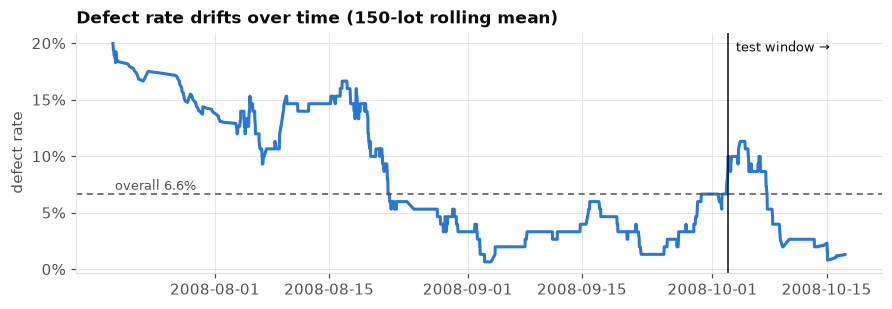

In [5]:
roll = pd.Series(y_all).rolling(150, center=True, min_periods=75).mean()
dev_cut_preview = int(round(DEV_FRAC * N))
fig, ax = plt.subplots(figsize=(8.2, 2.9))
ax.plot(df.timestamp, roll, color=C1, lw=2)
ax.axhline(PREVALENCE, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(df.timestamp.iloc[5], PREVALENCE + 0.004, f"overall {PREVALENCE:.1%}", color=INK2, fontsize=8.5)
ax.axvline(df.timestamp.iloc[dev_cut_preview], color=INK, lw=1)
ax.text(df.timestamp.iloc[dev_cut_preview], ax.get_ylim()[1] * 0.92, "  test window →", color=INK, fontsize=8.5)
ax.set_title("Defect rate drifts over time (150-lot rolling mean)", loc="left")
ax.set_ylabel("defect rate"); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
fig.tight_layout(); plt.show()

**Observations.** Rows are lots in time order. The defect rate drifts from roughly 13–15 % in July/August to roughly 2 % in October, so a
time-shuffled split mixes regimes, and its score says nothing about performance on *future* lots. Exactly 146 lots came through PS-L. In every one of them
`sensor_0` is exactly `0.0` and `sensor_1` is a firmware code. None of them is defective, although about 10 would be expected
if routing were independent of the label. That makes station identity a ready-made shortcut (see §B.6, residual risk).

# Part A — Audit of the release candidate

## A.1 · Reproduce the reported metric (release-candidate code, defects intact)
`original_recipe` is a line-for-line copy of `bnypi.ipynb` §3–§6, refactored into a function so it can also be re-run under an
honest protocol (§B.7). It keeps the `[N, 1, F]` loader, the flattening model, the broadcasting loss and the 0.5 threshold.

In [6]:
class OriginalWaferSAE(nn.Module):                     # verbatim from the release candidate
    def __init__(self, d_in: int, d_hid: int, d_lat: int):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(d_in, d_hid), nn.LayerNorm(d_hid), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(d_hid, d_hid // 2), nn.LayerNorm(d_hid // 2), nn.GELU(),
            nn.Linear(d_hid // 2, d_lat))
        self.decoder = nn.Sequential(
            nn.Linear(d_lat, d_hid // 2), nn.GELU(),
            nn.Linear(d_hid // 2, d_hid), nn.GELU(),
            nn.Linear(d_hid, d_in))
        self.head = nn.Linear(d_lat, 1)

    def forward(self, x):
        x = x.flatten(start_dim=1)                       # tolerate [B, F] or [B, C, F]  <- hides the defect
        z = self.encoder(x)
        return self.decoder(z), self.head(z).squeeze(-1), z

def original_recipe(X_train, y_train, X_test, y_test, epochs=40, verbose=True):
    """Release-candidate loaders + model + training loop + 0.5-threshold evaluation (defects intact)."""
    def make_loader(X, y, shuffle):
        Xt = torch.from_numpy(X).float().unsqueeze(1)                   # [N, 1, F]
        yt = torch.from_numpy(y).float()
        g = torch.Generator().manual_seed(SEED)
        return DataLoader(TensorDataset(Xt, yt), batch_size=64, shuffle=shuffle,
                          generator=g if shuffle else None, drop_last=shuffle)
    train_loader, test_loader = make_loader(X_train, y_train, True), make_loader(X_test, y_test, False)
    model = OriginalWaferSAE(X_train.shape[1], 256, 32).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    bce = nn.BCEWithLogitsLoss()
    hist = {"recon": [], "clf": []}; shapes = None
    for epoch in range(1, epochs + 1):
        model.train(); r_acc = c_acc = 0.0; nb = 0
        for batch_x, batch_y in train_loader:
            reconstructed, logits, _ = model(batch_x)
            diff = reconstructed - batch_x
            if shapes is None:
                shapes = dict(batch_x=tuple(batch_x.shape), reconstructed=tuple(reconstructed.shape),
                              diff=tuple(diff.shape), logits=tuple(logits.shape), batch_y=tuple(batch_y.shape))
            recon_loss = torch.mean(diff ** 2)
            clf_loss = bce(logits, batch_y)
            loss = recon_loss + 1.0 * clf_loss
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0); opt.step()
            r_acc += recon_loss.item(); c_acc += clf_loss.item(); nb += 1
        sched.step()
        hist["recon"].append(r_acc / nb); hist["clf"].append(c_acc / nb)
        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f"  epoch {epoch:02d} | recon {hist['recon'][-1]:.4f} | clf {hist['clf'][-1]:.4f}")
    model.eval(); probs = []
    with torch.no_grad():
        for xb, _ in test_loader:
            probs.append(torch.sigmoid(model(xb)[1]))
    probs = torch.cat(probs).numpy()
    preds = (probs >= 0.5).astype(int)
    m = dict(F1=f1_score(y_test, preds), precision=precision_score(y_test, preds, zero_division=0),
             recall=recall_score(y_test, preds), ROC_AUC=roc_auc_score(y_test, probs),
             AP=average_precision_score(y_test, probs), prevalence=y_test.mean())
    return model, probs, m, hist, shapes

# --- release-candidate preprocessing, exactly as written (fit on ALL rows, SMOTE before split) ---
seed_everything(SEED)
t0 = time.time()
rc_imputer = SimpleImputer(strategy="mean", keep_empty_features=True)
X_imp = rc_imputer.fit_transform(X_sensors)
rc_scaler = StandardScaler()
X_scaled = rc_scaler.fit_transform(X_imp)
X_bal, y_bal = SMOTE(sampling_strategy="auto", k_neighbors=5, random_state=SEED).fit_resample(X_scaled, y_all)
assert np.allclose(X_bal[:N], X_scaled)                  # imblearn appends synthetic rows after the originals
is_synth = np.arange(len(y_bal)) >= N
idx_tr, idx_te = train_test_split(np.arange(len(y_bal)), test_size=0.20, stratify=y_bal, random_state=SEED)
rc_model, rc_probs, rc_metrics, rc_hist, rc_shapes = original_recipe(X_bal[idx_tr], y_bal[idx_tr], X_bal[idx_te], y_bal[idx_te])
print(f"\nRELEASE CANDIDATE (reproduced, {time.time() - t0:.0f}s): " + " | ".join(f"{k} {v:.4f}" for k, v in rc_metrics.items()))

  epoch 01 | recon 0.6808 | clf 0.3019


  epoch 10 | recon 0.6749 | clf 0.0001


  epoch 20 | recon 0.6794 | clf 0.0000


  epoch 30 | recon 0.6800 | clf 0.0000


  epoch 40 | recon 0.6771 | clf 0.0000

RELEASE CANDIDATE (reproduced, 20s): F1 0.9915 | precision 0.9832 | recall 1.0000 | ROC_AUC 1.0000 | AP 1.0000 | prevalence 0.5000


The reported gate is reproduced. Every number above comes from a test set that is 50 % defective and mostly synthetic. The three
sections below take that score apart.

## A.2 · Bug 1 — data leakage (SMOTE before split · time-shuffled split · preprocessing fitted on all rows)

In [7]:
te_syn, te_pos = is_synth[idx_te], y_bal[idx_te] == 1
print(f"test rows: {len(idx_te)} | defect prevalence in test: {y_bal[idx_te].mean():.1%} (natural: {PREVALENCE:.1%})")
print(f"test defects: {te_pos.sum()} -> synthetic SMOTE rows: {(te_syn & te_pos).sum()} | real defective wafers: {(~te_syn & te_pos).sum()}")

# Near-duplicate leakage: SMOTE children of test defects sit in train (and vice versa)
nn1 = NearestNeighbors(n_neighbors=1).fit(X_bal[idx_tr])
d_te = nn1.kneighbors(X_bal[idx_te])[0][:, 0]
print("median distance to nearest TRAIN row (z-space): "
      f"synthetic test defects {np.median(d_te[te_syn & te_pos]):.2f} | real test defects {np.median(d_te[~te_syn & te_pos]):.2f} "
      f"| real test passes {np.median(d_te[~te_pos]):.2f}")

# Time-shuffled split: how much of the 'test' set predates training lots?
orig_row = np.where(is_synth, -1, np.arange(len(y_bal)))
tr_real, te_real = orig_row[idx_tr][orig_row[idx_tr] >= 0], orig_row[idx_te][orig_row[idx_te] >= 0]
later = (df.timestamp.values[tr_real][None, :] > df.timestamp.values[te_real][:, None]).any(1).mean()
print(f"real test lots for which the model trained on LATER lots: {later:.0%}")

# Preprocessing fitted on all rows: how different are the test-window statistics from the past?
cut = int(round(DEV_FRAC * N))
mu_dev, sd_dev = np.nanmean(X_sensors[:cut], 0), np.nanstd(X_sensors[:cut], 0)
shift = np.abs(np.nanmean(X_sensors[cut:], 0) - mu_dev) / np.where(sd_dev > 0, sd_dev, np.nan)
print(f"sensors whose last-20% mean moved > 0.5 SD vs the past: {(shift > 0.5).sum()} "
      f"(> 1 SD: {(shift > 1).sum()}) -> a scaler/imputer fitted on all rows encodes this future drift")

test rows: 586 | defect prevalence in test: 50.0% (natural: 6.6%)
test defects: 293 -> synthetic SMOTE rows: 274 | real defective wafers: 19
median distance to nearest TRAIN row (z-space): synthetic test defects 2.37 | real test defects 0.99 | real test passes 17.77
real test lots for which the model trained on LATER lots: 100%
sensors whose last-20% mean moved > 0.5 SD vs the past: 68 (> 1 SD: 14) -> a scaler/imputer fitted on all rows encodes this future drift


**Mechanism.** `SMOTE.fit_resample` runs on the full data set, so 274 of the 293 "test" defects are synthetic interpolations
between real defects. Their parents and siblings sit in the training set. Real test defects lie about 1 z-unit from a training
row (their own SMOTE children), while real passes lie about 18 units away. That gap is memorisation, not detection. The test set is also 50 % defective rather than 6.6 %,
the split ignores time (the model trains on lots that come after the lots it is graded on), and the imputer and scaler
are fitted on future lots whose distribution has drifted.

## A.3 · Bug 2 — corrupted reconstruction gradients (silent `[B,1,F]` vs `[B,F]` broadcast)

In [8]:
print("shapes in the release-candidate training step:", rc_shapes)
B = rc_shapes["batch_x"][0]
x = torch.from_numpy(X_scaled[:B].astype(np.float32))                    # a real batch, [B, F]
x_target = x.unsqueeze(1)                                                  # what the loader yields, [B, 1, F]
buggy = lambda r: torch.mean((r - x_target) ** 2).item()
right = lambda r: torch.mean((r - x) ** 2).item()
perfect, batch_mean = x.clone(), x.mean(0, keepdim=True).expand_as(x)
print(f"buggy loss  : perfect reconstruction {buggy(perfect):.4f} | predict batch-mean {buggy(batch_mean):.4f}")
print(f"correct loss: perfect reconstruction {right(perfect):.4f} | predict batch-mean {right(batch_mean):.4f}")

r = torch.randn(B, x.shape[1], requires_grad=True)
g_bug, = torch.autograd.grad(torch.mean((r - x_target) ** 2), r)
g_ok,  = torch.autograd.grad(torch.mean((r - x) ** 2), r)
print("buggy gradient == 2/(B·F)·(x̂ − batch-mean):",
      torch.allclose(g_bug, 2 * (r - x.mean(0, keepdim=True)) / (B * x.shape[1]), atol=1e-7),
      f"| cosine(buggy, correct) = {torch.nn.functional.cosine_similarity(g_bug.flatten(), g_ok.flatten(), dim=0):.3f}")
print(f"release-candidate recon loss, epoch 1 -> {len(rc_hist['recon'])}: {rc_hist['recon'][0]:.3f} -> {rc_hist['recon'][-1]:.3f} (never learns)")

shapes in the release-candidate training step: {'batch_x': (64, 1, 590), 'reconstructed': (64, 590), 'diff': (64, 64, 590), 'logits': (64,), 'batch_y': (64,)}
buggy loss  : perfect reconstruction 2.3043 | predict batch-mean 1.1522
correct loss: perfect reconstruction 0.0000 | predict batch-mean 1.1522
buggy gradient == 2/(B·F)·(x̂ − batch-mean): True | cosine(buggy, correct) = 0.707
release-candidate recon loss, epoch 1 -> 40: 0.681 -> 0.677 (never learns)


**Mechanism.** The loader adds a channel axis (`[B, 1, F]`). `forward` flattens it away, so the decoder returns `[B, F]`.
`reconstructed - batch_x` then broadcasts to `[B, B, F]` and compares every reconstruction with *every* wafer in the batch.
The gradient of that loss is exactly `2/(B·F)·(x̂ − batch-mean)`, so the decoder is trained to output the batch average. A perfect
reconstruction scores **twice as badly** as the trivial one, and the reconstruction term never decreases. No error is raised
because the shapes broadcast. The autoencoder half of the "supervised autoencoder" is dead weight that injects noise into
the shared encoder (the loss tensor is also 64× larger than needed).

## A.4 · Bug 3 — invariant blindness (PS-L sentinel and firmware codes scaled as genuine measurements)

In [9]:
s0_fill = rc_imputer.statistics_[0]
print(f"sensor_0 mean/std used by the release candidate: {rc_scaler.mean_[0]:.1f} / {rc_scaler.scale_[0]:.1f} "
      f"(genuine: {g0.mean():.1f} / {g0.std(ddof=0):.1f})")
print(f"sensor_1 mean/std used by the release candidate: {rc_scaler.mean_[1]:.1f} / {rc_scaler.scale_[1]:.1f} "
      f"(genuine: {g1.mean():.1f} / {g1.std(ddof=0):.1f})")
print(f"-> genuine variation squashed {rc_scaler.scale_[0] / g0.std(ddof=0):.1f}x (sensor_0) and "
      f"{rc_scaler.scale_[1] / g1.std(ddof=0):.1f}x (sensor_1): standardized std of real readings = "
      f"{X_scaled[~is_legacy, 0].std():.3f} / {X_scaled[~is_legacy, 1].std():.3f} instead of 1")
print(f"mean-imputed value written into the 6 missing sensor_0 readings: {s0_fill:.1f} "
      f"(lower than {np.mean(g0.values > s0_fill):.0%} of genuine readings, i.e. a fabricated out-of-range value)")
print("PS-L rows in z-space: sensor_0 ->", np.unique(X_scaled[is_legacy, 0].round(2)),
      "| sensor_1 codes ->", np.unique(X_scaled[is_legacy, 1].round(2)),
      "(ordinal-encoded as if code 300 were 'more' than code 100)")

sensor_0 mean/std used by the release candidate: 2732.1 / 878.8 (genuine: 3014.0 / 74.3)
sensor_1 mean/std used by the release candidate: 2280.5 / 674.2 (genuine: 2495.7 / 79.8)
-> genuine variation squashed 11.8x (sensor_0) and 8.4x (sensor_1): standardized std of real readings = 0.087 / 0.119 instead of 1
mean-imputed value written into the 6 missing sensor_0 readings: 2732.1 (lower than 100% of genuine readings, i.e. a fabricated out-of-range value)
PS-L rows in z-space: sensor_0 -> [-3.11] | sensor_1 codes -> [-3.23 -3.09 -2.94] (ordinal-encoded as if code 300 were 'more' than code 100)


**Mechanism.** The release candidate treats PS-L's sentinel (`0.0`) and firmware error codes (`100/200/300`) as physical
readings. Mean and standard deviation for both channels are dominated by these fake values. Real process variation is compressed
roughly 10× (the model is effectively blind to genuine `sensor_0`/`sensor_1` signal), the six genuinely missing `sensor_0`
readings are imputed with a value no real wafer has, and categorical codes are given a false order and magnitude.
The network also gets a free "station-identity" shortcut (PS-L ⇒ pass, see §0) that holds only by accident in this data.

## A.5 · Further defects (lower severity)
| Location | Defect | Consequence |
|---|---|---|
| §6 `preds = probs >= 0.5` | fixed threshold, never tuned | on a model trained at 50 % prevalence, 0.5 is meaningless at 6.6 % |
| §2–§6 | no validation data, fixed 40 epochs, no model selection | the train/test split was the only check, and it leaked |
| §6 | point estimates only | a 6.6 % test window holds about 20 defects, so F1 has a CI of roughly ±0.15 |
| §7 gate | F1 ≥ 0.90 on a balanced, synthetic test set | the gate cannot fail and measures nothing deployable |
| §7 artifacts | `preprocessor.joblib` fitted on all rows, no PS-L handling, no threshold saved | production inference would reproduce Bug 3 and use an arbitrary cut-off |

# Part B — Repaired pipeline

## B.1 · Chronological split (no lot is ever scored by a model that saw its future)
Development = first 80 % of lots (model fitting, hyper-parameter and threshold selection). **Test = last 20 %**, touched once.
Boundaries are moved forward so that lots sharing a timestamp never straddle a split.

In [10]:
TS = df["timestamp"].to_numpy()
def time_cut(frac: float) -> int:
    i = int(round(frac * N))
    while 0 < i < N and TS[i] == TS[i - 1]:
        i += 1
    return i

DEV_END  = time_cut(DEV_FRAC)
dev_idx  = np.arange(0, DEV_END)
test_idx = np.arange(DEV_END, N)
assert TS[dev_idx].max() < TS[test_idx].min()
y_test = y_all[test_idx]
print(f"development: {len(dev_idx)} lots, {TS[0]} -> {TS[DEV_END - 1]}, defects {y_all[dev_idx].sum()} ({y_all[dev_idx].mean():.2%})")
print(f"test       : {len(test_idx)} lots, {TS[DEV_END]} -> {TS[-1]}, defects {y_test.sum()} ({y_test.mean():.2%}) "
      f"<- natural prevalence of this period, NOT resampled; {is_legacy[test_idx].sum()} PS-L lots")

development: 1254 lots, 2008-07-19T11:55:00.000000 -> 2008-10-02T20:54:00.000000, defects 87 (6.94%)
test       : 313 lots, 2008-10-02T21:32:00.000000 -> 2008-10-17T06:07:00.000000, defects 17 (5.43%) <- natural prevalence of this period, NOT resampled; 26 PS-L lots


## B.2 · Legacy-aware, causally fitted preprocessor
* **PS-L rows** (`sensor_0 == 0.0`): `sensor_0` and `sensor_1` are *not measurements*. They are removed from the continuous block
  (masked, never scaled, never filled with a fabricated reading, excluded from the reconstruction target). The firmware code becomes
  a categorical feature (`is_PSL`, one-hot `code_100/200/300`, plus `code_unknown` for unseen firmware).
  Code statistics never enter any scaler.
* **Continuous channels:** drop channels that are constant or more than 50 % missing *in the training window*. Then apply a rank-based
  quantile→N(0,1) transform fitted on training rows only. It is robust to SECOM's heavy tails and bounds future out-of-range drift
  (chosen over z-scoring on rolling-origin CV, see `experiments/`).
* **Missing readings** are masked: input value 0 plus an observation mask, so the masked MSE ignores them. The model never learns to
  reproduce imputed numbers.

In [11]:
class LegacyAwarePreprocessor:
    """Fit on the past only; transform anything. Returns (features [n, K + 5], observed-mask [n, K])."""

    def __init__(self, max_missing=HP["max_missing"], scaling="quantile", legacy_aware=True):
        self.max_missing, self.scaling, self.legacy_aware = max_missing, scaling, legacy_aware

    def _split(self, frame):
        X = frame[SENSOR_COLS].to_numpy(np.float64, copy=True)
        legacy = frame["sensor_0"].to_numpy() == LEGACY_SENTINEL
        code = np.where(legacy, frame["sensor_1"].to_numpy(), np.nan)
        if self.legacy_aware:
            X[legacy, 0] = np.nan          # sentinel: no reading exists
            X[legacy, 1] = np.nan          # firmware code: categorical, handled below
        return X, legacy, code

    def fit(self, frame):
        X, _, _ = self._split(frame)
        missing, sd = np.isnan(X).mean(0), np.nanstd(X, 0)
        self.keep_ = (missing <= self.max_missing) & (np.nan_to_num(sd) > 0)
        self.columns_ = [c for c, k in zip(SENSOR_COLS, self.keep_) if k]
        Xk = X[:, self.keep_]
        if self.scaling == "quantile":
            self.qt_ = QuantileTransformer(n_quantiles=min(1000, len(Xk)), output_distribution="normal",
                                           random_state=0).fit(Xk)          # NaNs ignored in fit
        else:                                                                # z-scoring (ablation only)
            self.mu_, self.sd_ = np.nanmean(Xk, 0), np.nanstd(Xk, 0)
        self.n_cont_ = int(self.keep_.sum())
        self.cat_names_ = (["is_PSL"] + [f"code_{int(c)}" for c in LEGACY_CODES] + ["code_unknown"]
                           if self.legacy_aware else [])
        return self

    def transform(self, frame):
        X, legacy, code = self._split(frame)
        X = X[:, self.keep_]
        observed = ~np.isnan(X)
        Z = self.qt_.transform(X) if self.scaling == "quantile" else np.clip((X - self.mu_) / self.sd_, -5, 5)
        Z = np.where(observed, Z, 0.0)                                       # masked, not imputed
        parts = [Z]
        if self.legacy_aware:
            known = np.isin(code, LEGACY_CODES)
            parts.append(np.column_stack([legacy] + [legacy & (code == c) for c in LEGACY_CODES]
                                         + [legacy & ~known]).astype(np.float64))
        return np.hstack(parts).astype(np.float32), observed.astype(np.float32)

# sanity checks on the development fit
_prep = LegacyAwarePreprocessor().fit(df.iloc[dev_idx])
_X, _M = _prep.transform(df.iloc[dev_idx])
_leg = is_legacy[dev_idx]
print(f"kept {_prep.n_cont_}/{len(SENSOR_COLS)} continuous channels + {len(_prep.cat_names_)} categorical PS-L columns -> input dim {_X.shape[1]}")
for s in ("sensor_0", "sensor_1"):
    j = _prep.columns_.index(s)
    assert (_M[_leg, j] == 0).all() and (_X[_leg, j] == 0).all()       # no fabricated value, excluded from recon loss
    print(f"{s}: PS-L rows masked ({int(_leg.sum())} rows, mask=0, value=0); genuine rows standardized std={_X[~_leg & (_M[:, j] > 0), j].std():.2f}")
print("PS-L one-hot code counts (dev):", dict(zip(_prep.cat_names_, _X[:, _prep.n_cont_:].sum(0).astype(int))))

kept 444/590 continuous channels + 5 categorical PS-L columns -> input dim 449
sensor_0: PS-L rows masked (120 rows, mask=0, value=0); genuine rows standardized std=1.02
sensor_1: PS-L rows masked (120 rows, mask=0, value=0); genuine rows standardized std=1.02
PS-L one-hot code counts (dev): {'is_PSL': np.int64(120), 'code_100': np.int64(50), 'code_200': np.int64(30), 'code_300': np.int64(40), 'code_unknown': np.int64(0)}


## B.3 · Model and loss (shape-safe)
The supervised-autoencoder architecture is unchanged. Inputs are flat `[B, F]`. The decoder reconstructs only the continuous channels, and every
loss operand is asserted to have the exact same shape, so silent broadcasting is impossible. Class imbalance is handled by
`pos_weight = n_pass / n_fail` *of the training window* instead of synthetic oversampling.

In [12]:
class WaferSAE(nn.Module):
    def __init__(self, d_in, d_rec, d_hid=HP["hidden"], d_lat=HP["latent"], p=HP["dropout"]):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(d_in, d_hid), nn.LayerNorm(d_hid), nn.GELU(), nn.Dropout(p),
            nn.Linear(d_hid, d_hid // 2), nn.LayerNorm(d_hid // 2), nn.GELU(),
            nn.Linear(d_hid // 2, d_lat))
        self.decoder = nn.Sequential(
            nn.Linear(d_lat, d_hid // 2), nn.GELU(),
            nn.Linear(d_hid // 2, d_hid), nn.GELU(),
            nn.Linear(d_hid, d_rec))
        self.head = nn.Linear(d_lat, 1)

    def forward(self, x):
        if x.dim() != 2:
            raise ValueError(f"WaferSAE expects [batch, features], got {tuple(x.shape)}")
        z = self.encoder(x)
        return self.decoder(z), self.head(z).squeeze(-1), z

def sae_loss(x_hat, x_cont, observed, logits, y, bce, lam=HP["lambda_clf"]):
    assert x_hat.shape == x_cont.shape == observed.shape, (x_hat.shape, x_cont.shape, observed.shape)
    assert logits.shape == y.shape and logits.dim() == 1, (logits.shape, y.shape)
    recon = ((x_hat - x_cont) ** 2 * observed).sum() / observed.sum().clamp_min(1.0)   # observed cells only
    clf = bce(logits, y)
    return recon + lam * clf, recon, clf

# shape + gradient unit test: per-sample reconstruction gradient must depend only on that sample
_m = WaferSAE(_X.shape[1], _prep.n_cont_)
xb, mb = torch.from_numpy(_X[:8]), torch.from_numpy(_M[:8])
x_hat, logits, z = _m(xb)
print("x", tuple(xb.shape), "| x_hat", tuple(x_hat.shape), "| logits", tuple(logits.shape), "| z", tuple(z.shape))
x_hat_leaf = x_hat.detach().requires_grad_(True)
loss, _, _ = sae_loss(x_hat_leaf, xb[:, :_prep.n_cont_], mb, logits.detach(), torch.zeros(8), nn.BCEWithLogitsLoss())
g, = torch.autograd.grad(loss, x_hat_leaf)
expected = 2 * (x_hat_leaf - xb[:, :_prep.n_cont_]) * mb / mb.sum()
assert torch.allclose(g, expected, atol=1e-6)
print("gradient check passed: dL/dx̂_i = 2·(x̂_i − x_i)·mask_i / #observed (no cross-sample terms)")
try:
    _m(xb.unsqueeze(1))
except ValueError as e:
    print("3-D input now rejected:", e)

x (8, 449) | x_hat (8, 444) | logits (8,) | z (8, 32)
gradient check passed: dL/dx̂_i = 2·(x̂_i − x_i)·mask_i / #observed (no cross-sample terms)
3-D input now rejected: WaferSAE expects [batch, features], got (8, 1, 449)


## B.4 · Training utilities

In [13]:
def predict_proba(models, X):
    models = models if isinstance(models, (list, tuple)) else [models]
    xt = torch.from_numpy(X).to(DEVICE)
    out = []
    for m in models:
        m.eval()
        with torch.no_grad():
            out.append(torch.sigmoid(m(xt)[1]).cpu().numpy())
    return np.mean(out, axis=0)

def recon_mse(model, X, M):
    model.eval()
    with torch.no_grad():
        x_hat = model(torch.from_numpy(X))[0]
        Mt = torch.from_numpy(M)
        return float((((x_hat - torch.from_numpy(X)[:, :M.shape[1]]) ** 2) * Mt).sum() / Mt.sum())

def train_sae(X, M, y, *, seed, epochs, buggy_recon=False, monitor=None, monitor_recon=None, hp=HP):
    """Train one WaferSAE for `epochs` epochs of a cosine schedule spanning hp['max_epochs'] epochs."""
    seed_everything(seed)
    n_cont = M.shape[1]
    model = WaferSAE(X.shape[1], n_cont, hp["hidden"], hp["latent"], hp["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=hp["max_epochs"])
    bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - y).sum() / y.sum(), dtype=torch.float32))
    Xt, Mt, yt = torch.from_numpy(X), torch.from_numpy(M), torch.from_numpy(y.astype(np.float32))
    gen = torch.Generator().manual_seed(seed)
    log = {"probs": [], "recon": []}
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt), generator=gen)                      # shuffled mini-batches, [B, F]
        for i in range(0, len(perm), hp["batch_size"]):
            b = perm[i:i + hp["batch_size"]]
            xb, mb, yb = Xt[b], Mt[b], yt[b]
            x_hat, logits, _ = model(xb)
            if buggy_recon:     # ablation only: re-inject the release-candidate broadcast
                loss = torch.mean((x_hat - xb[:, :n_cont].unsqueeze(1)) ** 2) + hp["lambda_clf"] * bce(logits, yb)
            else:
                loss, _, _ = sae_loss(x_hat, xb[:, :n_cont], mb, logits, yb, bce, hp["lambda_clf"])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
        sched.step()
        if monitor is not None:
            log["probs"].append(predict_proba(model, monitor))
        if monitor_recon is not None:
            log["recon"].append(recon_mse(model, *monitor_recon))
    return model, log

def fit_ensemble(train_idx, *, epochs, seeds=SEEDS, prep=None, prep_fit_idx=None, monitor_idx=None, **kw):
    """Fit preprocessor (on the training window unless an ablation overrides it) and a seed ensemble."""
    prep = (prep or LegacyAwarePreprocessor()).fit(df.iloc[train_idx if prep_fit_idx is None else prep_fit_idx])
    X, M = prep.transform(df.iloc[train_idx])
    X_mon = prep.transform(df.iloc[monitor_idx])[0] if monitor_idx is not None else None
    models, logs = [], []
    for s in seeds:
        m, log = train_sae(X, M, y_all[train_idx], seed=s, epochs=epochs, monitor=X_mon, **kw)
        models.append(m); logs.append(log)
    return prep, models, logs

def f1_optimal_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(thr[i]), float(f1[i])

## B.5 · Model selection on the past only — rolling-origin validation
Four expanding-window folds inside the development period. Each one trains on all lots before a 10 % block and validates on that block
(40–50 %, 50–60 %, 60–70 %, 70–80 % of the timeline). This yields 22 validation defects instead of the 11 a single
hold-out would give.
* **Epoch budget:** the epoch that maximises the fold-averaged validation AP (5-epoch moving average to damp noise).
* **Decision threshold:** maximises F1 (the release metric) on the pooled out-of-time validation scores at that epoch.
  Folds are pooled because 2-defect folds give degenerate per-fold F1 curves. All fold models share the same class weighting,
  so their probability scales are comparable. This is the same procedure as sklearn's `TunedThresholdClassifierCV` with refit.

In [14]:
t0 = time.time()
folds = [(np.arange(0, time_cut(a)), np.arange(time_cut(a), time_cut(b))) for a, b in zip(CV_EDGES[:-1], CV_EDGES[1:])]
cv_probs = []
for k, (tr, va) in enumerate(folds):
    _, _, logs = fit_ensemble(tr, epochs=HP["max_epochs"], monitor_idx=va)
    cv_probs.append(np.mean([np.stack(l["probs"]) for l in logs], axis=0))       # [epochs, n_val] ensemble mean
    print(f"fold {k + 1}: train {len(tr):4d} lots ({y_all[tr].sum()} defects) -> validate {len(va)} lots ({y_all[va].sum()} defects)")

E = HP["max_epochs"]
ap_curves  = np.array([[average_precision_score(y_all[va], P[e]) for e in range(E)] for (_, va), P in zip(folds, cv_probs)])
auc_curves = np.array([[roc_auc_score(y_all[va], P[e]) for e in range(E)] for (_, va), P in zip(folds, cv_probs)])
smooth_ap = pd.Series(ap_curves.mean(0)).rolling(5, center=True, min_periods=1).mean().to_numpy()
BEST_EPOCH = int(np.argmax(smooth_ap)) + 1

oof_p = np.concatenate([P[BEST_EPOCH - 1] for P in cv_probs])
oof_y = np.concatenate([y_all[va] for _, va in folds])
THRESHOLD, oof_f1 = f1_optimal_threshold(oof_y, oof_p)
oof_pred = oof_p >= THRESHOLD
print(f"\nselected epoch budget: {BEST_EPOCH} | fold-mean val AP {ap_curves.mean(0)[BEST_EPOCH - 1]:.3f} "
      f"| fold-mean val ROC-AUC {auc_curves.mean(0)[BEST_EPOCH - 1]:.3f}")
print("per-fold val AP :", np.round(ap_curves[:, BEST_EPOCH - 1], 3), "| per-fold val AUC:", np.round(auc_curves[:, BEST_EPOCH - 1], 3))
print(f"pooled out-of-time validation: {len(oof_y)} lots, {oof_y.sum()} defects ({oof_y.mean():.2%}) | AP {average_precision_score(oof_y, oof_p):.3f} "
      f"| ROC-AUC {roc_auc_score(oof_y, oof_p):.3f}")
print(f"decision threshold (max F1 on validation): {THRESHOLD:.4f} -> val F1 {oof_f1:.3f}, precision {precision_score(oof_y, oof_pred):.3f}, "
      f"recall {recall_score(oof_y, oof_pred):.3f}, alarm rate {oof_pred.mean():.1%} | {time.time() - t0:.0f}s")

fold 1: train  627 lots (65 defects) -> validate 157 lots (2 defects)


fold 2: train  784 lots (67 defects) -> validate 156 lots (9 defects)


fold 3: train  940 lots (76 defects) -> validate 157 lots (2 defects)


fold 4: train 1097 lots (78 defects) -> validate 157 lots (9 defects)

selected epoch budget: 38 | fold-mean val AP 0.094 | fold-mean val ROC-AUC 0.613
per-fold val AP : [0.054 0.238 0.018 0.066] | per-fold val AUC: [0.71  0.707 0.494 0.541]
pooled out-of-time validation: 627 lots, 22 defects (3.51%) | AP 0.062 | ROC-AUC 0.545
decision threshold (max F1 on validation): 0.1418 -> val F1 0.196, precision 0.172, recall 0.227, alarm rate 4.6% | 36s


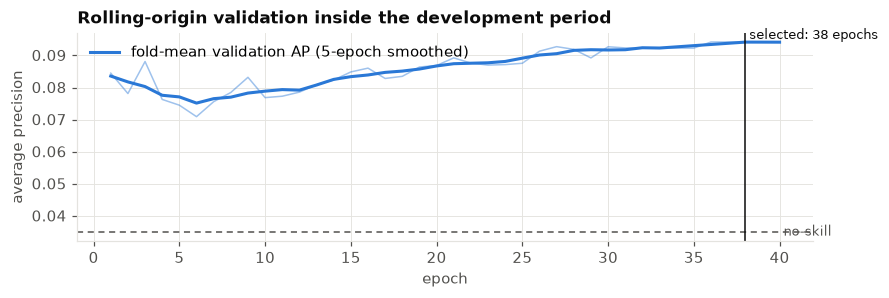

In [15]:
fig, ax = plt.subplots(figsize=(8.2, 2.8))
ep = np.arange(1, E + 1)
ax.plot(ep, ap_curves.mean(0), color=C1, lw=1, alpha=0.45)
ax.plot(ep, smooth_ap, color=C1, lw=2, label="fold-mean validation AP (5-epoch smoothed)")
ax.axhline(oof_y.mean(), color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(E, oof_y.mean(), " no-skill", color=INK2, va="center", fontsize=8.5)
ax.axvline(BEST_EPOCH, color=INK, lw=1)
ax.text(BEST_EPOCH, smooth_ap.max(), f" selected: {BEST_EPOCH} epochs", color=INK, va="bottom", fontsize=8.5)
ax.set_xlabel("epoch"); ax.set_ylabel("average precision")
ax.set_title("Rolling-origin validation inside the development period", loc="left")
ax.legend(loc="upper left"); fig.tight_layout(); plt.show()

## B.6 · Final model and honest test evaluation (natural prevalence, evaluated once)
The preprocessor and the 5-seed ensemble are refitted on the full development period with the selected epoch budget and threshold, then
scored once on the test window. That window holds the 313 most recent lots at their natural defect rate. It was not resampled, not rebalanced and not used for any choice.

In [16]:
t0 = time.time()
prep_final, models_final, _ = fit_ensemble(dev_idx, epochs=BEST_EPOCH)
X_test, M_test = prep_final.transform(df.iloc[test_idx])
p_test = predict_proba(models_final, X_test)
print(f"final ensemble trained on {len(dev_idx)} lots in {time.time() - t0:.0f}s")

def point_metrics(y, p, thr, target_prev=None):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    out = dict(AP=average_precision_score(y, p), ROC_AUC=roc_auc_score(y, p),
               precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
               F1=f1_score(y, pred, zero_division=0), MCC=matthews_corrcoef(y, pred),
               balanced_acc=balanced_accuracy_score(y, pred), FPR=fp / max(fp + tn, 1),
               alarm_rate=pred.mean(), TP=tp, FP=fp, FN=fn, TN=tn)
    if target_prev is not None:   # re-weight negatives so the test window has exactly the target prevalence
        w_neg = y.sum() * (1 - target_prev) / (target_prev * (1 - y).sum())
        w = np.where(y == 1, 1.0, w_neg)
        prec_adj = tp / max(tp + w_neg * fp, 1e-12)
        out.update(AP_at_target=average_precision_score(y, p, sample_weight=w), precision_at_target=prec_adj,
                   F1_at_target=2 * prec_adj * out["recall"] / max(prec_adj + out["recall"], 1e-12))
    return out

def bootstrap_ci(y, p, thr, n_boot=2000, seed=SEED):
    rng, rows = np.random.default_rng(seed), []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            rows.append(point_metrics(y[i], p[i], thr))
    q = pd.DataFrame(rows).quantile([0.025, 0.975])
    return {k: (q.loc[0.025, k], q.loc[0.975, k]) for k in ("AP", "ROC_AUC", "precision", "recall", "F1", "MCC")}

test_m  = point_metrics(y_test, p_test, THRESHOLD, target_prev=PREVALENCE)
test_ci = bootstrap_ci(y_test, p_test, THRESHOLD)
print(f"\nTEST WINDOW: {len(y_test)} lots, {y_test.sum()} defective -> prevalence {y_test.mean():.2%} (natural, untouched); threshold {THRESHOLD:.4f}")
for k in ("AP", "ROC_AUC", "precision", "recall", "F1", "MCC"):
    lo, hi = test_ci[k]
    print(f"  {k:<10s} {test_m[k]:.3f}   95% bootstrap CI [{lo:.3f}, {hi:.3f}]")
print(f"  balanced accuracy {test_m['balanced_acc']:.3f} | FPR {test_m['FPR']:.3f} | alarm rate {test_m['alarm_rate']:.1%}")
print(f"  confusion: TP={test_m['TP']} FP={test_m['FP']} FN={test_m['FN']} TN={test_m['TN']}")
print(f"  no-skill AP (= prevalence): {y_test.mean():.3f}")
print(f"\nre-weighted to the data set's natural prevalence {PREVALENCE:.2%}: AP {test_m['AP_at_target']:.3f} | "
      f"precision {test_m['precision_at_target']:.3f} | recall {test_m['recall']:.3f} | F1 {test_m['F1_at_target']:.3f}")

final ensemble trained on 1254 lots in 12s



TEST WINDOW: 313 lots, 17 defective -> prevalence 5.43% (natural, untouched); threshold 0.1418
  AP         0.233   95% bootstrap CI [0.078, 0.436]
  ROC_AUC    0.698   95% bootstrap CI [0.560, 0.833]
  precision  0.286   95% bootstrap CI [0.000, 0.667]
  recall     0.118   95% bootstrap CI [0.000, 0.300]
  F1         0.167   95% bootstrap CI [0.000, 0.381]
  MCC        0.154   95% bootstrap CI [-0.034, 0.385]
  balanced accuracy 0.550 | FPR 0.017 | alarm rate 2.2%
  confusion: TP=2 FP=5 FN=15 TN=291
  no-skill AP (= prevalence): 0.054

re-weighted to the data set's natural prevalence 6.64%: AP 0.255 | precision 0.331 | recall 0.118 | F1 0.174


In [17]:
# Reference models on the identical causal features (threshold-free comparison)
Xd, _ = prep_final.transform(df.iloc[dev_idx])
lr  = LogisticRegression(C=1e-3, class_weight="balanced", max_iter=5000).fit(Xd, y_all[dev_idx])
rf  = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced_subsample",
                             n_jobs=-1, random_state=SEED).fit(Xd, y_all[dev_idx])
p_lr, p_rf = lr.predict_proba(X_test)[:, 1], rf.predict_proba(X_test)[:, 1]
ref = pd.DataFrame({
    "no-skill":                {"AP": y_test.mean(), "ROC_AUC": 0.5},
    "logistic regression":     {"AP": average_precision_score(y_test, p_lr), "ROC_AUC": roc_auc_score(y_test, p_lr)},
    "random forest":           {"AP": average_precision_score(y_test, p_rf), "ROC_AUC": roc_auc_score(y_test, p_rf)},
    "WaferSAE (repaired)":     {"AP": test_m["AP"], "ROC_AUC": test_m["ROC_AUC"]},
}).T.round(3)
print(ref.to_string())

# PS-L subgroup: no PS-L defect exists anywhere, so only the false-alarm side is measurable
leg_t = is_legacy[test_idx]
pred_t = p_test >= THRESHOLD
print(f"\nPS-L lots in test: {leg_t.sum()} (defects: {y_test[leg_t].sum()}) | mean score PS-L {p_test[leg_t].mean():.3f} vs "
      f"modern passes {p_test[~leg_t & (y_test == 0)].mean():.3f} | FPR PS-L {pred_t[leg_t].mean():.3f} vs modern {pred_t[~leg_t & (y_test == 0)].mean():.3f}")

                        AP  ROC_AUC
no-skill             0.054    0.500
logistic regression  0.187    0.669
random forest        0.100    0.634
WaferSAE (repaired)  0.233    0.698

PS-L lots in test: 26 (defects: 0) | mean score PS-L 0.000 vs modern passes 0.008 | FPR PS-L 0.000 vs modern 0.019


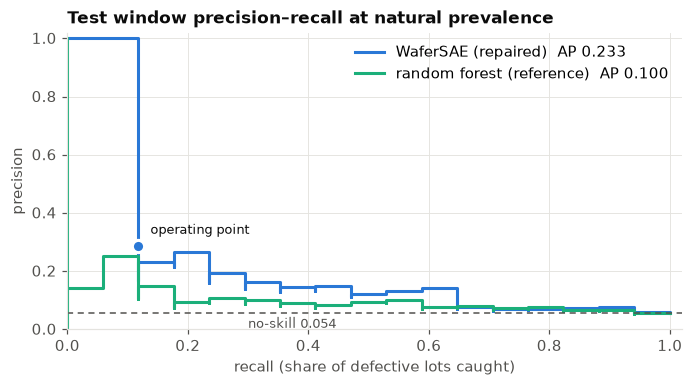

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for p, c, name in ((p_test, C1, "WaferSAE (repaired)"), (p_rf, C3, "random forest (reference)")):
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.step(rc, pr, where="post", color=c, lw=2, label=f"{name}  AP {average_precision_score(y_test, p):.3f}")
ax.axhline(y_test.mean(), color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(0.30, y_test.mean() - 0.012, f"no-skill {y_test.mean():.3f}", color=INK2, ha="left", va="top", fontsize=8.5)
ax.plot(test_m["recall"], test_m["precision"], "o", ms=8, color=C1, mec="white", mew=2)
ax.annotate("operating point", (test_m["recall"], test_m["precision"]), textcoords="offset points", xytext=(8, 8), fontsize=8.5, color=INK)
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02); ax.set_xlabel("recall (share of defective lots caught)"); ax.set_ylabel("precision")
ax.set_title("Test window precision–recall at natural prevalence", loc="left")
ax.legend(loc="upper right"); fig.tight_layout(); plt.show()

In [19]:
# DESCRIPTIVE ONLY: the trade-off the ranking offers on the test window. Cut-offs are read off the test scores, so these
# are not deployable operating points (the deployable one is the validation-chosen threshold above).
order = np.argsort(-p_test)
budget_df = pd.DataFrame([{"alarm budget": f"{b:.0%}", "lots flagged": int(round(b * len(p_test))),
                           "defects caught": int(y_test[order[:int(round(b * len(p_test)))]].sum()),
                           "recall": y_test[order[:int(round(b * len(p_test)))]].sum() / y_test.sum(),
                           "precision": y_test[order[:int(round(b * len(p_test)))]].mean()}
                          for b in (0.02, 0.05, 0.10, 0.20)])
print(f"validation alarm rate at the chosen threshold: {oof_pred.mean():.1%} | test alarm rate: {test_m['alarm_rate']:.1%}  <- score scale drifts between refits")
print(budget_df.round(3).to_string(index=False))

validation alarm rate at the chosen threshold: 4.6% | test alarm rate: 2.2%  <- score scale drifts between refits
alarm budget  lots flagged  defects caught  recall  precision
          2%             6               2   0.118      0.333
          5%            16               4   0.235      0.250
         10%            31               5   0.294      0.161
         20%            63               8   0.471      0.127


## B.7 · Ablations: re-inject each defect into the repaired pipeline
Same test window, epoch budget and seeds. Only one thing changes per row. The last block re-runs the **release-candidate recipe**
under the leaky protocol and under an honest one. The model is the same in both, so the gap is the size of the leak.

In [20]:
t0 = time.time()
def ensemble_test_metrics(same_features=False, **kw):
    prep, models, _ = fit_ensemble(dev_idx, epochs=BEST_EPOCH, **kw)
    Xt, Mt = prep.transform(df.iloc[test_idx])
    p = predict_proba(models, Xt)
    # reconstruction MSE is only comparable when the feature space is identical to the repaired one
    mse = np.mean([recon_mse(m, Xt, Mt) for m in models]) if same_features else np.nan
    return dict(test_AP=average_precision_score(y_test, p), test_ROC_AUC=roc_auc_score(y_test, p), test_recon_MSE=mse)

abl = {"repaired pipeline": dict(test_AP=test_m["AP"], test_ROC_AUC=test_m["ROC_AUC"],
                                 test_recon_MSE=np.mean([recon_mse(m, X_test, M_test) for m in models_final]))}
abl["+ Bug 2: broadcast recon loss"]          = ensemble_test_metrics(same_features=True, buggy_recon=True)
abl["+ Bug 3: PS-L sentinel/codes as numbers"] = ensemble_test_metrics(prep=LegacyAwarePreprocessor(legacy_aware=False))
abl["+ Bug 1c: preprocessor fit incl. test"]   = ensemble_test_metrics(prep_fit_idx=np.arange(N))
abl["design: z-scoring instead of quantile"]   = ensemble_test_metrics(prep=LegacyAwarePreprocessor(scaling="standard"))
abl_df = pd.DataFrame(abl).T
print(abl_df.round(3).to_string()); print(f"({time.time() - t0:.0f}s)")

                                         test_AP  test_ROC_AUC  test_recon_MSE
repaired pipeline                          0.233         0.698           1.101
+ Bug 2: broadcast recon loss              0.212         0.671           1.425
+ Bug 3: PS-L sentinel/codes as numbers    0.235         0.696             NaN
+ Bug 1c: preprocessor fit incl. test      0.148         0.673             NaN
design: z-scoring instead of quantile      0.131         0.714             NaN
(59s)


In [21]:
# Bug 1b: time-shuffled evaluation. Same repaired pipeline, stratified random 5-fold CV over ALL lots at natural prevalence
t0 = time.time()
oof_rand = np.zeros(N)
for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(np.zeros(N), y_all):
    prep, models, _ = fit_ensemble(tr, epochs=BEST_EPOCH, seeds=SEEDS[:3])
    oof_rand[va] = predict_proba(models, prep.transform(df.iloc[va])[0])
print(f"time-shuffled 5-fold CV (non-causal, all periods mixed): AP {average_precision_score(y_all, oof_rand):.3f} | ROC-AUC {roc_auc_score(y_all, oof_rand):.3f}")
print(f"out-of-time rolling validation (dev, fold mean)        : AP {ap_curves.mean(0)[BEST_EPOCH - 1]:.3f} | ROC-AUC {auc_curves.mean(0)[BEST_EPOCH - 1]:.3f}")
print(f"chronological test window                              : AP {test_m['AP']:.3f} | ROC-AUC {test_m['ROC_AUC']:.3f}  ({time.time() - t0:.0f}s)")

# Release-candidate recipe under an HONEST protocol: past-only imputer/scaler, SMOTE on the training window only, natural-prevalence test
t0 = time.time()
seed_everything(SEED)
imp_h = SimpleImputer(strategy="mean", keep_empty_features=True).fit(X_sensors[dev_idx])
sc_h  = StandardScaler().fit(imp_h.transform(X_sensors[dev_idx]))
Xd_h, Xt_h = sc_h.transform(imp_h.transform(X_sensors[dev_idx])), sc_h.transform(imp_h.transform(X_sensors[test_idx]))
Xd_bal, yd_bal = SMOTE(k_neighbors=5, random_state=SEED).fit_resample(Xd_h, y_all[dev_idx])
_, rc_honest_probs, rc_honest, rc_honest_hist, _ = original_recipe(Xd_bal, yd_bal, Xt_h, y_test, verbose=False)
print("\nrelease-candidate recipe | leaky protocol : " + " | ".join(f"{k} {v:.3f}" for k, v in rc_metrics.items()))
print("release-candidate recipe | honest protocol: " + " | ".join(f"{k} {v:.3f}" for k, v in rc_honest.items()) + f"  ({time.time() - t0:.0f}s)")

time-shuffled 5-fold CV (non-causal, all periods mixed): AP 0.161 | ROC-AUC 0.712
out-of-time rolling validation (dev, fold mean)        : AP 0.094 | ROC-AUC 0.613
chronological test window                              : AP 0.233 | ROC-AUC 0.698  (36s)



release-candidate recipe | leaky protocol : F1 0.992 | precision 0.983 | recall 1.000 | ROC_AUC 1.000 | AP 1.000 | prevalence 0.500
release-candidate recipe | honest protocol: F1 0.000 | precision 0.000 | recall 0.000 | ROC_AUC 0.713 | AP 0.137 | prevalence 0.054  (13s)


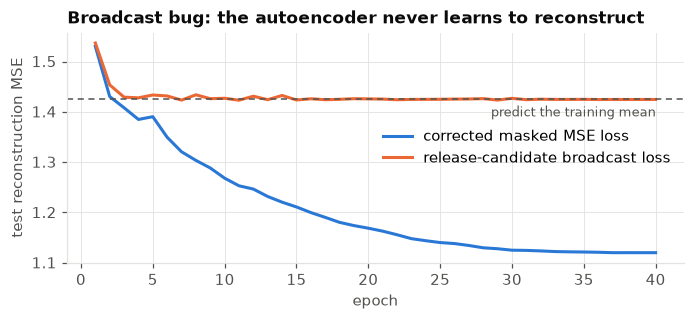

test recon MSE after 40 epochs: corrected 1.120 | broadcast 1.425 | mean-predictor 1.425


In [22]:
# Reconstruction quality with the broadcast loss vs the corrected loss (correctly-measured masked MSE on the test window)
_prep_c = LegacyAwarePreprocessor().fit(df.iloc[dev_idx])
Xc, Mc = _prep_c.transform(df.iloc[dev_idx]); Xtc, Mtc = _prep_c.transform(df.iloc[test_idx])
_, log_ok  = train_sae(Xc, Mc, y_all[dev_idx], seed=SEED, epochs=HP["max_epochs"], monitor_recon=(Xtc, Mtc))
_, log_bug = train_sae(Xc, Mc, y_all[dev_idx], seed=SEED, epochs=HP["max_epochs"], monitor_recon=(Xtc, Mtc), buggy_recon=True)
mu_train = (Xc[:, :Mc.shape[1]] * Mc).sum(0) / np.maximum(Mc.sum(0), 1)          # per-channel training mean
mean_baseline = float((((Xtc[:, :Mtc.shape[1]] - mu_train) ** 2) * Mtc).sum() / Mtc.sum())

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ep = np.arange(1, HP["max_epochs"] + 1)
ax.plot(ep, log_ok["recon"], color=C1, lw=2, label="corrected masked MSE loss")
ax.plot(ep, log_bug["recon"], color=C2, lw=2, label="release-candidate broadcast loss")
ax.axhline(mean_baseline, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(HP["max_epochs"], mean_baseline - 0.012, "predict the training mean", color=INK2, ha="right", va="top", fontsize=8.5)
ax.set_xlabel("epoch"); ax.set_ylabel("test reconstruction MSE")
ax.set_title("Broadcast bug: the autoencoder never learns to reconstruct", loc="left")
ax.legend(loc="center right"); fig.tight_layout(); plt.show()
print(f"test recon MSE after {HP['max_epochs']} epochs: corrected {log_ok['recon'][-1]:.3f} | broadcast {log_bug['recon'][-1]:.3f} | mean-predictor {mean_baseline:.3f}")

**Reading the ablations.** The numbers above are from a 17-defect test window, so differences under about 0.1 AP are within noise (see the CIs in §B.6).
* **Bug 1 (leakage)** is the whole story behind the reported score. The *same* release-candidate recipe drops from F1 0.99 (leaky protocol) to F1 0.00 at its
  0.5 threshold and AP 0.14 under an honest protocol. Fitting only the preprocessor on all rows moved test AP to 0.148, which is *down*. Leakage does not
  reliably inflate any single number. It makes the estimate invalid in either direction, which is why causality is enforced rather than measured.
* **Bug 2 (broadcast)**: with the broadcast loss, test reconstruction MSE equals that of predicting the training mean (1.425), so the decoder learns nothing.
  With the corrected loss it falls to 1.12. Test AP drops 0.233 → 0.212 when the bug is re-injected.
* **Bug 3 (PS-L)**: re-injecting it *under rank scaling* leaves test AP unchanged (0.235 vs 0.233). Ranks are immune to the variance-squashing, and every
  PS-L lot in the test window is a pass, so this window cannot show the damage. The repair is required by the tool-matching contract. It protects the
  genuine `sensor_0/1` signal (squashed 12× under the release candidate's z-scoring, §A.4) and keeps fabricated values out of the model. It is a correctness
  fix, not a metric gain.
* **Rank vs z-scoring**: test AP 0.233 vs 0.131, consistent with the development-period selection.
* **Ranking power is modest.** The repaired SAE's ROC-AUC (0.698) is no better than the release-candidate recipe trained honestly (0.713). The repair's gains are
  in the high-risk tail (AP 0.233 vs 0.137), a decoder that works, and a threshold chosen on data.

## B.8 · Release gate (re-evaluated honestly) and artifacts

In [23]:
GATE_F1 = 0.90
passed = test_m["F1"] >= GATE_F1
print(f"Release gate (F1 >= {GATE_F1} on the natural-prevalence test window): F1 = {test_m['F1']:.3f} "
      f"[95% CI {test_ci['F1'][0]:.3f}-{test_ci['F1'][1]:.3f}] -> {'PASSED' if passed else 'FAILED -> NO-GO'}")

os.makedirs("artifacts", exist_ok=True); os.makedirs("results", exist_ok=True)
for s, m in zip(SEEDS, models_final):
    torch.save(m.state_dict(), f"artifacts/wafer_sae_seed{s}.pt")
joblib.dump({"preprocessor": prep_final, "threshold": THRESHOLD, "epochs": BEST_EPOCH, "seeds": SEEDS,
             "legacy_sentinel": LEGACY_SENTINEL, "legacy_codes": LEGACY_CODES,
             "trained_through": str(TS[DEV_END - 1])}, "artifacts/preprocessor.joblib")

f = lambda v: None if pd.isna(v) else float(round(float(v), 4))
results = {
    "release_candidate_reproduced": {k: f(v) for k, v in rc_metrics.items()},
    "release_candidate_honest_protocol": {k: f(v) for k, v in rc_honest.items()},
    "split": {"dev_lots": int(len(dev_idx)), "test_lots": int(len(test_idx)), "test_defects": int(y_test.sum()),
              "test_prevalence": f(y_test.mean()), "dataset_prevalence": f(PREVALENCE),
              "test_window": [str(TS[DEV_END]), str(TS[-1])]},
    "selection": {"epochs": BEST_EPOCH, "threshold": f(THRESHOLD), "val_pooled_AP": f(average_precision_score(oof_y, oof_p)),
                  "val_pooled_ROC_AUC": f(roc_auc_score(oof_y, oof_p)), "val_F1": f(oof_f1)},
    "test": {k: (f(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in test_m.items()},
    "test_95ci": {k: [f(a), f(b)] for k, (a, b) in test_ci.items()},
    "reference_models_test": {k: {kk: f(vv) for kk, vv in v.items()} for k, v in ref.T.to_dict().items()},
    "ablations_test": {k: {kk: f(vv) for kk, vv in v.items()} for k, v in abl_df.T.to_dict().items()},
    "test_alarm_budgets_descriptive": budget_df.round(4).to_dict(orient="records"),
    "time_shuffled_cv": {"AP": f(average_precision_score(y_all, oof_rand)), "ROC_AUC": f(roc_auc_score(y_all, oof_rand))},
    "release_gate": {"F1_threshold": GATE_F1, "passed": bool(passed)},
}
with open("results/metrics.json", "w") as fh:
    json.dump(results, fh, indent=2)
print("wrote artifacts/ (weights, preprocessor + threshold) and results/metrics.json")

Release gate (F1 >= 0.9 on the natural-prevalence test window): F1 = 0.167 [95% CI 0.000-0.381] -> FAILED -> NO-GO
wrote artifacts/ (weights, preprocessor + threshold) and results/metrics.json


## Answers to the required audit questions

In [24]:
print(f"""THREE SILENT BUGS
 1. Data leakage: SMOTE before the split, a time-shuffled split, and imputer/scaler fitted on all rows.
    Test was {rc_metrics['prevalence']:.0%} defective and mostly synthetic. FIX: chronological split first, all statistics
    fitted on the past window only, no synthetic data, threshold and epochs chosen on past-only rolling validation.
 2. Corrupted loss gradients: [B,1,F] target vs [B,F] reconstruction broadcast to [B,B,F]; the gradient pulled every
    reconstruction toward the batch mean. FIX: flat [B,F] tensors, masked MSE, hard shape assertions, gradient unit test.
 3. Invariant blindness: PS-L sentinel sensor_0=0.0 and firmware codes sensor_1 in {{100,200,300}} scaled and imputed as
    measurements (genuine variance squashed ~{rc_scaler.scale_[0] / g0.std(ddof=0):.0f}x, fabricated imputations, ordinal codes).
    FIX: sentinel/code masked out of the continuous block (never scaled, imputed or reconstructed), code one-hot + PS-L flag.

TRUE METRICS OF THE REPAIRED MODEL (test window: {len(y_test)} most recent lots, {y_test.sum()} defective, prevalence {y_test.mean():.2%})
  ROC-AUC {test_m['ROC_AUC']:.3f} [{test_ci['ROC_AUC'][0]:.3f}, {test_ci['ROC_AUC'][1]:.3f}] | AP {test_m['AP']:.3f} [{test_ci['AP'][0]:.3f}, {test_ci['AP'][1]:.3f}] (no-skill {y_test.mean():.3f})
  at threshold {THRESHOLD:.4f}: precision {test_m['precision']:.3f} | recall {test_m['recall']:.3f} | F1 {test_m['F1']:.3f} [{test_ci['F1'][0]:.3f}, {test_ci['F1'][1]:.3f}] | MCC {test_m['MCC']:.3f}
  re-weighted to {PREVALENCE:.2%} prevalence: precision {test_m['precision_at_target']:.3f} | F1 {test_m['F1_at_target']:.3f} | AP {test_m['AP_at_target']:.3f}
  release gate F1 >= 0.90: {'PASSED' if passed else 'FAILED -> recommendation: NO-GO'}""")

THREE SILENT BUGS
 1. Data leakage: SMOTE before the split, a time-shuffled split, and imputer/scaler fitted on all rows.
    Test was 50% defective and mostly synthetic. FIX: chronological split first, all statistics
    fitted on the past window only, no synthetic data, threshold and epochs chosen on past-only rolling validation.
 2. Corrupted loss gradients: [B,1,F] target vs [B,F] reconstruction broadcast to [B,B,F]; the gradient pulled every
    reconstruction toward the batch mean. FIX: flat [B,F] tensors, masked MSE, hard shape assertions, gradient unit test.
 3. Invariant blindness: PS-L sentinel sensor_0=0.0 and firmware codes sensor_1 in {100,200,300} scaled and imputed as
    measurements (genuine variance squashed ~12x, fabricated imputations, ordinal codes).
    FIX: sentinel/code masked out of the continuous block (never scaled, imputed or reconstructed), code one-hot + PS-L flag.

TRUE METRICS OF THE REPAIRED MODEL (test window: 313 most recent lots, 17 defective, preval